C:\Users\20234503\AppData\Local\Temp\ipykernel_472\523425858.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_full = cm.get_cmap("Reds")


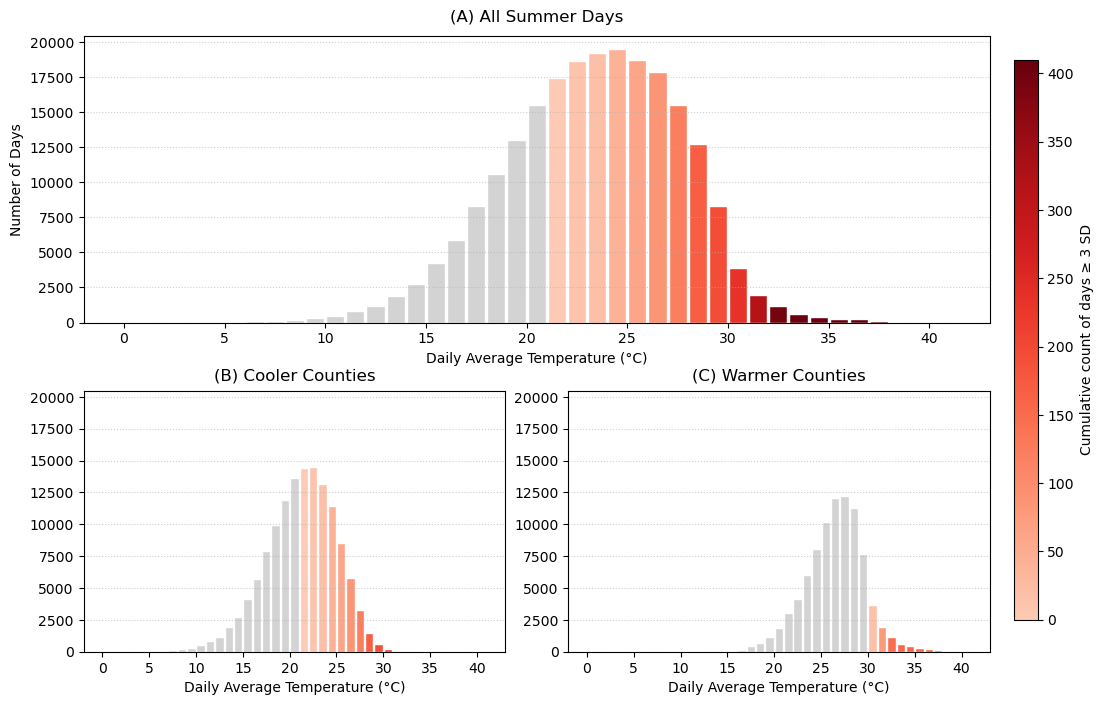

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.colors import Normalize
from matplotlib import gridspec

# --- Load data
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes"
df = pd.read_csv(directory + r"\Data\Weather Data\Weather_Labour_Unrest_Event.csv")

# --- Filter to summer months
df["date"] = pd.to_datetime(df["date"])
summer = df[df["date"].dt.month.isin([6, 7, 8])].copy()

# --- Variables
temp_col = "nn_tavg"
extreme_cols = ["tavg_norm_above_3SD"]
summer["extreme"] = summer[extreme_cols].sum(axis=1).clip(0, 1)

# --- Set up bins (shared)
bins = np.arange(np.floor(summer[temp_col].min()), np.ceil(summer[temp_col].max()) + 1, 1)
bin_centres = (bins[:-1] + bins[1:]) / 2

# --- Helper to compute totals and cumulative extremes
def get_counts(data):
    total_counts, _ = np.histogram(data[temp_col], bins=bins)
    extreme_counts, _ = np.histogram(data.loc[data["extreme"] == 1, temp_col], bins=bins)
    cum_extreme = np.cumsum(extreme_counts)
    return total_counts, cum_extreme

# --- Datasets: overall, below median (1), above median (2)
total_all, cum_all = get_counts(summer)
total_below, cum_below = get_counts(summer[summer["CDD_median"] == 1])
total_above, cum_above = get_counts(summer[summer["CDD_median"] == 2])

# --- Global colour scaling across all panels
max_cum = int(max(
    cum_all.max() if cum_all.size else 0,
    cum_below.max() if cum_below.size else 0,
    cum_above.max() if cum_above.size else 0
))
cmap_full = cm.get_cmap("Reds")
cmap = colors.LinearSegmentedColormap.from_list("Reds_trunc", cmap_full(np.linspace(0.2, 1, 10)))
norm = Normalize(vmin=0, vmax=max(1, max_cum))  # avoid zero range

def make_bar_colors(total_counts, cum_extreme):
    # Grey if no days in bin or cumulative count still 0
    return [
        cmap(norm(v)) if (v > 0 and total_counts[i] > 0) else "lightgray"
        for i, v in enumerate(cum_extreme)
    ]

# --- Figure layout: 2 rows, top spans both columns
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.1, 1.0], hspace=0.25, wspace=0.15)

ax_top   = fig.add_subplot(gs[0, :])   # full width
ax_left  = fig.add_subplot(gs[1, 0], sharey=ax_top)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_top)

# --- Panel A: All summer days (top)
colors_all = make_bar_colors(total_all, cum_all)
ax_top.bar(bin_centres, total_all, width=0.9, color=colors_all, edgecolor="white", align="center")
ax_top.set_title("(A) All Summer Days", pad=10)
ax_top.set_xlabel("Daily Average Temperature (°C)")
ax_top.set_ylabel("Number of Days")
ax_top.grid(axis="y", linestyle=":", alpha=0.6)

# --- Panel B: Below Median (bottom-left)
colors_below = make_bar_colors(total_below, cum_below)
ax_left.bar(bin_centres, total_below, width=0.9, color=colors_below, edgecolor="white", align="center")
ax_left.set_title("(B) Cooler Counties", pad=8)
ax_left.set_xlabel("Daily Average Temperature (°C)")
ax_left.grid(axis="y", linestyle=":", alpha=0.6)

# --- Panel C: Above Median (bottom-right)
colors_above = make_bar_colors(total_above, cum_above)
ax_right.bar(bin_centres, total_above, width=0.9, color=colors_above, edgecolor="white", align="center")
ax_right.set_title("(C) Warmer Counties", pad=8)
ax_right.set_xlabel("Daily Average Temperature (°C)")
ax_right.grid(axis="y", linestyle=":", alpha=0.6)

# --- Single shared colourbar on the right
fig.subplots_adjust(right=0.88)  # make room on the right
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.70])  # [left, bottom, width, height]
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Cumulative count of days ≥ 3 SD")

plt.show()

C:\Users\20234503\AppData\Local\Temp\ipykernel_22652\3074657005.py:49: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_full = cm.get_cmap("Reds")
C:\Users\20234503\AppData\Local\Temp\ipykernel_22652\3074657005.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_full = cm.get_cmap("Reds")


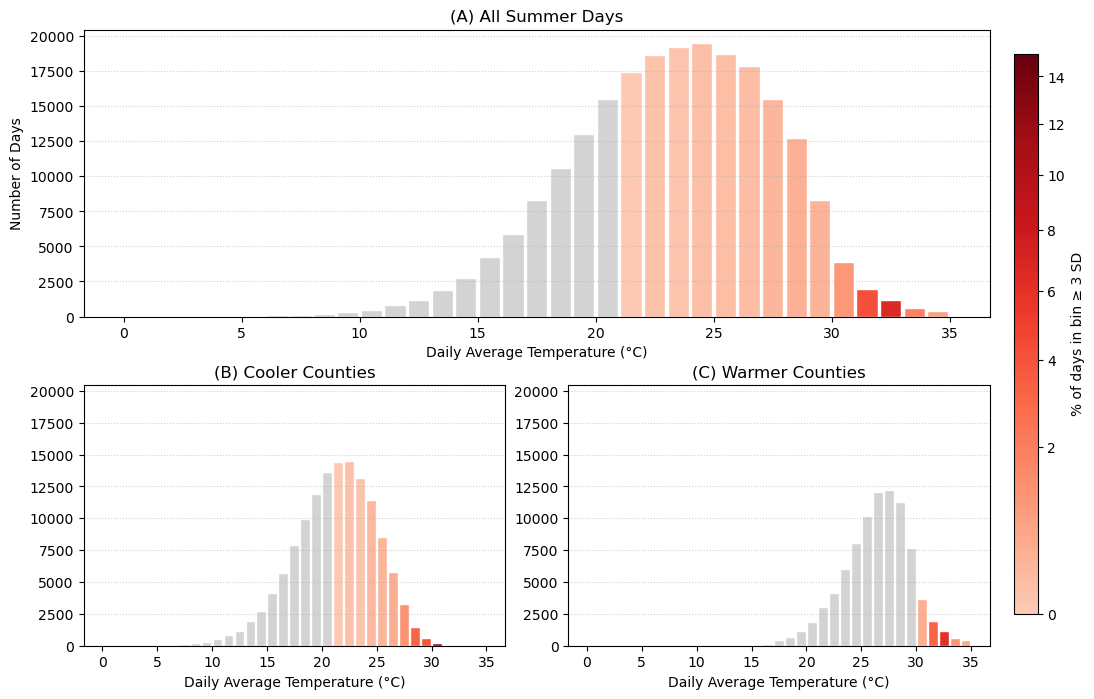

Highest % of extreme days (All Summer Days):
  Temperature bin centre: 32.5°C
  Percentage: 6.62%
Highest % of extreme days (Cooler Counties):
  Temperature bin centre: 33.5°C
  Percentage: 100.00%
Highest % of extreme days (Warmer Counties):
  Temperature bin centre: 32.5°C
  Percentage: 6.14%


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.colors import Normalize
from matplotlib import gridspec

# --- Load data
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes"
df = pd.read_csv(directory + r"\Data\Weather Data\Weather_Labour_Unrest_Event.csv")

# --- Filter to summer months
df["date"] = pd.to_datetime(df["date"])
summer = df[df["date"].dt.month.isin([6, 7, 8])].copy()

# --- Variables
temp_col = "nn_tavg"
extreme_cols = ["tavg_norm_above_3SD"]
summer["extreme"] = summer[extreme_cols].sum(axis=1).clip(0, 1)

# --- Shared bins
summer["temp_clipped"] = summer[temp_col].clip(upper=35)

bins = np.arange(
    np.floor(summer["temp_clipped"].min()),
    35 + 1,
    1
)
#bins = np.arange(np.floor(summer[temp_col].min()), np.ceil(summer[temp_col].max()) + 1, 1)

#bins = np.arange(np.floor(summer[temp_col].min()), np.ceil(summer[temp_col].max()) + 1, 1)
bin_centres = (bins[:-1] + bins[1:]) / 2

# --- Compute % extreme per bin
def get_percentage_extreme(data):
    total_counts, _ = np.histogram(data[temp_col], bins=bins)
    extreme_counts, _ = np.histogram(data.loc[data["extreme"] == 1, temp_col], bins=bins)
    pct = np.divide(extreme_counts, total_counts, out=np.zeros_like(extreme_counts, dtype=float), where=total_counts > 0)
    return total_counts, pct * 100  # return percent

# Groups
total_all, pct_all = get_percentage_extreme(summer)
total_below, pct_below = get_percentage_extreme(summer[summer["CDD_median"] == 1])
total_above, pct_above = get_percentage_extreme(summer[summer["CDD_median"] == 2])

# --- Colour scale for percentages
max_pct = max(pct_all.max(), pct_below.max(), pct_above.max())
max_pct = max(max_pct, 1)  # avoid zero range
cmap_full = cm.get_cmap("Reds")
cmap = colors.LinearSegmentedColormap.from_list("Reds_trunc", cmap_full(np.linspace(0.2, 1, 256)))
#norm = Normalize(vmin=0, vmax=max_pct)
from matplotlib.colors import PowerNorm

vmin, vmax = 0.0, 15.0     # full visible range 0–10%
gamma = 0.6                # <1 emphasises small values (0–5%)

cmap_full = cm.get_cmap("Reds")
cmap = colors.LinearSegmentedColormap.from_list(
    "Reds_trunc", cmap_full(np.linspace(0.2, 1, 256))
)

norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)

def make_bar_colors(total_counts, pct_extreme):
    colors_list = []
    for t, pct in zip(total_counts, pct_extreme):
        if t == 0 or pct == 0:
            colors_list.append("lightgray")
        else:
            colors_list.append(cmap(norm(pct)))
    return colors_list

# --- Figure layout
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.1, 1.0], hspace=0.25, wspace=0.15)

ax_top   = fig.add_subplot(gs[0, :])
ax_left  = fig.add_subplot(gs[1, 0], sharey=ax_top)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_top)

# --- Panel A
colors_all = make_bar_colors(total_all, pct_all)
ax_top.bar(bin_centres, total_all, width=0.9, color=colors_all, edgecolor="white")
ax_top.set_title("(A) All Summer Days")
ax_top.set_xlabel("Daily Average Temperature (°C)")
ax_top.set_ylabel("Number of Days")
ax_top.grid(axis="y", linestyle=":", alpha=0.6)

# --- Panel B
colors_below = make_bar_colors(total_below, pct_below)
ax_left.bar(bin_centres, total_below, width=0.9, color=colors_below, edgecolor="white")
ax_left.set_title("(B) Cooler Counties")
ax_left.set_xlabel("Daily Average Temperature (°C)")
ax_left.grid(axis="y", linestyle=":", alpha=0.6)

# --- Panel C
colors_above = make_bar_colors(total_above, pct_above)
ax_right.bar(bin_centres, total_above, width=0.9, color=colors_above, edgecolor="white")
ax_right.set_title("(C) Warmer Counties")
ax_right.set_xlabel("Daily Average Temperature (°C)")
ax_right.grid(axis="y", linestyle=":", alpha=0.6)

# --- Colourbar (percentage)
fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.70])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("% of days in bin ≥ 3 SD")

plt.show()

#Other Summary Statistics
max_pct_all = pct_all.max()
idx_all = pct_all.argmax()
temp_bin_all = bin_centres[idx_all]

print("Highest % of extreme days (All Summer Days):")
print(f"  Temperature bin centre: {temp_bin_all}°C")
print(f"  Percentage: {max_pct_all:.2f}%")

max_pct_below = pct_below.max()
idx_below = pct_below.argmax()
temp_bin_below = bin_centres[idx_below]

print("Highest % of extreme days (Cooler Counties):")
print(f"  Temperature bin centre: {temp_bin_below}°C")
print(f"  Percentage: {max_pct_below:.2f}%")

max_pct_above = pct_above.max()
idx_above = pct_above.argmax()
temp_bin_above = bin_centres[idx_above]

print("Highest % of extreme days (Warmer Counties):")
print(f"  Temperature bin centre: {temp_bin_above}°C")
print(f"  Percentage: {max_pct_above:.2f}%")


C:\Users\20234503\AppData\Local\Temp\ipykernel_22652\2482720574.py:84: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_full = cm.get_cmap("Reds")


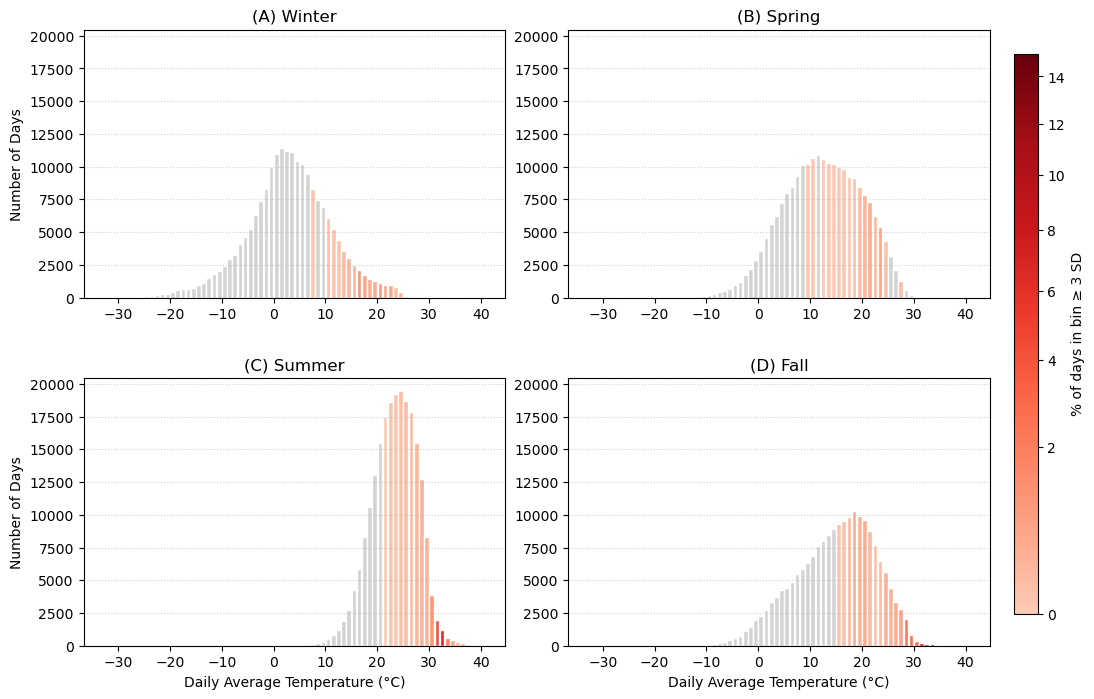

In [1]:
# Appendix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.colors import Normalize, PowerNorm
from matplotlib import gridspec

# --- Load data
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes"
df = pd.read_csv(directory + r"\Data\Weather Data\Weather_Labour_Unrest_Event.csv")

# ---------- 1) Season variable ----------
if 'month' not in df.columns:
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'], errors='coerce')
        df['month'] = df['date'].dt.month
    else:
        raise KeyError("Need 'date' or 'month' to compute seasons.")

df['season'] = np.select(
    [
        df['month'].isin([12, 1, 2]),   # Winter
        df['month'].isin([3, 4, 5]),    # Spring
        df['month'].isin([6, 7, 8]),    # Summer
        df['month'].isin([9, 10, 11]),  # Fall
    ],
    [1, 2, 3, 4],
    default=np.nan
)

# --- Variables
temp_col = "nn_tavg"
extreme_cols = ["tavg_norm_above_3SD"]   # adjust if your actual column name differs

# Extreme indicator (>= 3 SD) for all days
df["extreme"] = df[extreme_cols].sum(axis=1).clip(0, 1)

# Seasonal subsets
winter = df[df["season"] == 1].copy()
spring = df[df["season"] == 2].copy()
summer = df[df["season"] == 3].copy()
fall   = df[df["season"] == 4].copy()

# --- Shared bins across ALL seasons
temp_min = np.floor(df[temp_col].min())
temp_max = np.ceil(df[temp_col].max())
bins = np.arange(temp_min, temp_max + 1, 1)
bin_centres = (bins[:-1] + bins[1:]) / 2

# --- Compute % extreme per bin
def get_percentage_extreme(data):
    total_counts, _ = np.histogram(data[temp_col], bins=bins)
    extreme_counts, _ = np.histogram(
        data.loc[data["extreme"] == 1, temp_col],
        bins=bins
    )
    pct = np.divide(
        extreme_counts,
        total_counts,
        out=np.zeros_like(extreme_counts, dtype=float),
        where=total_counts > 0
    )
    return total_counts, pct * 100  # percent

# For each season
total_winter, pct_winter = get_percentage_extreme(winter)
total_spring, pct_spring = get_percentage_extreme(spring)
total_summer, pct_summer = get_percentage_extreme(summer)
total_fall,   pct_fall   = get_percentage_extreme(fall)

# --- Colour scale for percentages
max_pct = max(
    pct_winter.max(),
    pct_spring.max(),
    pct_summer.max(),
    pct_fall.max()
)
max_pct = max(max_pct, 1)  # avoid zero range

vmin, vmax = 0.0, 15.0     # visible % range
gamma = 0.6                # <1 emphasises small values

cmap_full = cm.get_cmap("Reds")
cmap = colors.LinearSegmentedColormap.from_list(
    "Reds_trunc", cmap_full(np.linspace(0.2, 1, 256))
)
norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)

def make_bar_colors(total_counts, pct_extreme):
    colors_list = []
    for t, pct in zip(total_counts, pct_extreme):
        if t == 0 or pct == 0:
            colors_list.append("lightgray")
        else:
            colors_list.append(cmap(norm(pct)))
    return colors_list

# --- Figure layout: 4 panels (one per season)
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 2, hspace=0.3, wspace=0.15)

ax_winter = fig.add_subplot(gs[0, 0])
ax_spring = fig.add_subplot(gs[0, 1], sharey=ax_winter)
ax_summer = fig.add_subplot(gs[1, 0], sharey=ax_winter)
ax_fall   = fig.add_subplot(gs[1, 1], sharey=ax_winter)

# Panel (A) Winter
colors_winter = make_bar_colors(total_winter, pct_winter)
ax_winter.bar(bin_centres, total_winter, width=0.9,
              color=colors_winter, edgecolor="white")
ax_winter.set_title("(A) Winter")
ax_winter.set_ylabel("Number of Days")
ax_winter.grid(axis="y", linestyle=":", alpha=0.6)

# Panel (B) Spring
colors_spring = make_bar_colors(total_spring, pct_spring)
ax_spring.bar(bin_centres, total_spring, width=0.9,
              color=colors_spring, edgecolor="white")
ax_spring.set_title("(B) Spring")
ax_spring.grid(axis="y", linestyle=":", alpha=0.6)

# Panel (C) Summer
colors_summer = make_bar_colors(total_summer, pct_summer)
ax_summer.bar(bin_centres, total_summer, width=0.9,
              color=colors_summer, edgecolor="white")
ax_summer.set_title("(C) Summer")
ax_summer.set_xlabel("Daily Average Temperature (°C)")
ax_summer.set_ylabel("Number of Days")
ax_summer.grid(axis="y", linestyle=":", alpha=0.6)

# Panel (D) Fall
colors_fall = make_bar_colors(total_fall, pct_fall)
ax_fall.bar(bin_centres, total_fall, width=0.9,
            color=colors_fall, edgecolor="white")
ax_fall.set_title("(D) Fall")
ax_fall.set_xlabel("Daily Average Temperature (°C)")
ax_fall.grid(axis="y", linestyle=":", alpha=0.6)

# --- Colourbar (percentage of days in bin ≥ 3 SD)
fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.70])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("% of days in bin ≥ 3 SD")

plt.show()



